# Regression: understand the baseline before the model

This dataset is synthetic. A linear relationship was built into its generator; the exercise teaches evaluation rather than facts about students.

## 1–2. Question and data understanding
Can weekly study hours improve on a prediction that always uses the training mean?

In [1]:
import pandas as pd
from IPython.display import Image, display
from model import ROOT, FEATURES, load_students, train_and_evaluate, run

data = load_students(ROOT / 'data/students.csv')
display(data.head())
display(data.isna().sum().to_frame('missing'))

,student_id,study_hours,exam_score
0,S001,0.5,27.5
1,S002,4.2,63.0
2,S003,7.9,77.5
3,S004,2.1,44.5
4,S005,5.8,59.0


,missing
student_id,0
study_hours,2
exam_score,0


## 3–4. Split, prepare, and fit
Read train_and_evaluate in model.py. It splits first, then fits both the median imputer and model only on training rows. Student IDs are not features.

In [2]:
model, scores, train, predictions = train_and_evaluate(data)
print('Training rows:', len(train), '| test rows:', len(predictions))
print('Any shared IDs?', bool(set(train.student_id) & set(predictions.student_id)))
print('Median learned from training:', scores['training_median_hours'])

Training rows: 96 | test rows: 24
Any shared IDs? False
Median learned from training: 5.5


## 5. Evaluate on held-out observations
Compare both models on the same test set. MAE and RMSE are in score points. A negative R² is possible.

In [3]:
pd.DataFrame({name: scores[name] for name in ['linear_regression', 'mean_baseline']}).T

,mae,rmse,r2
linear_regression,5.894893,6.872489,0.767571
mean_baseline,13.715278,17.394901,-0.489039


### Check an error calculation by hand
A residual is actual minus predicted. MAE takes the absolute values, then averages them.

In [4]:
display(predictions.head())
manual_mae = (predictions.exam_score - predictions.predicted_score).abs().mean()
print('Manual MAE:', manual_mae)
print('Library MAE:', scores['linear_regression']['mae'])
assert abs(manual_mae - scores['linear_regression']['mae']) < 1e-10

,student_id,study_hours,exam_score,predicted_score,residual
44,S045,1.8,47.0,45.602920,1.397080
47,S048,3.4,43.0,53.295248,-10.295248
4,S005,5.8,59.0,64.833739,-5.833739
55,S056,4.5,58.5,58.583723,-0.083723
26,S027,1.7,34.5,45.122150,-10.622150


Manual MAE: 5.894892689527172
Library MAE: 5.894892689527172


### Interpret the fitted line
The slope describes association inside this synthetic dataset. It does not prove that an extra hour causes a particular score change.

In [5]:
print(f"predicted score = {scores['intercept']:.2f} + {scores['slope']:.2f} × hours")
model.predict(pd.DataFrame({'study_hours': [4.0]}))

predicted score = 36.95 + 4.81 × hours


array([56.17987069])

## 6. Deliver a reproducible report
Inspect residuals as well as a single headline metric.

{
  "training_rows": 96,
  "test_rows": 24,
  "linear_regression": {
    "mae": 5.894892689527172,
    "rmse": 6.872488637637046,
    "r2": 0.7675710300743858
  },
  "mean_baseline": {
    "mae": 13.715277777777777,
    "rmse": 17.394900798358183,
    "r2": -0.48903912530863636
  },
  "training_median_hours": 5.5,
  "intercept": 36.949051394222096,
  "slope": 4.807704823738219,
  "example_prediction": {
    "hours": 4,
    "score": 56.179870689174976
  }
}

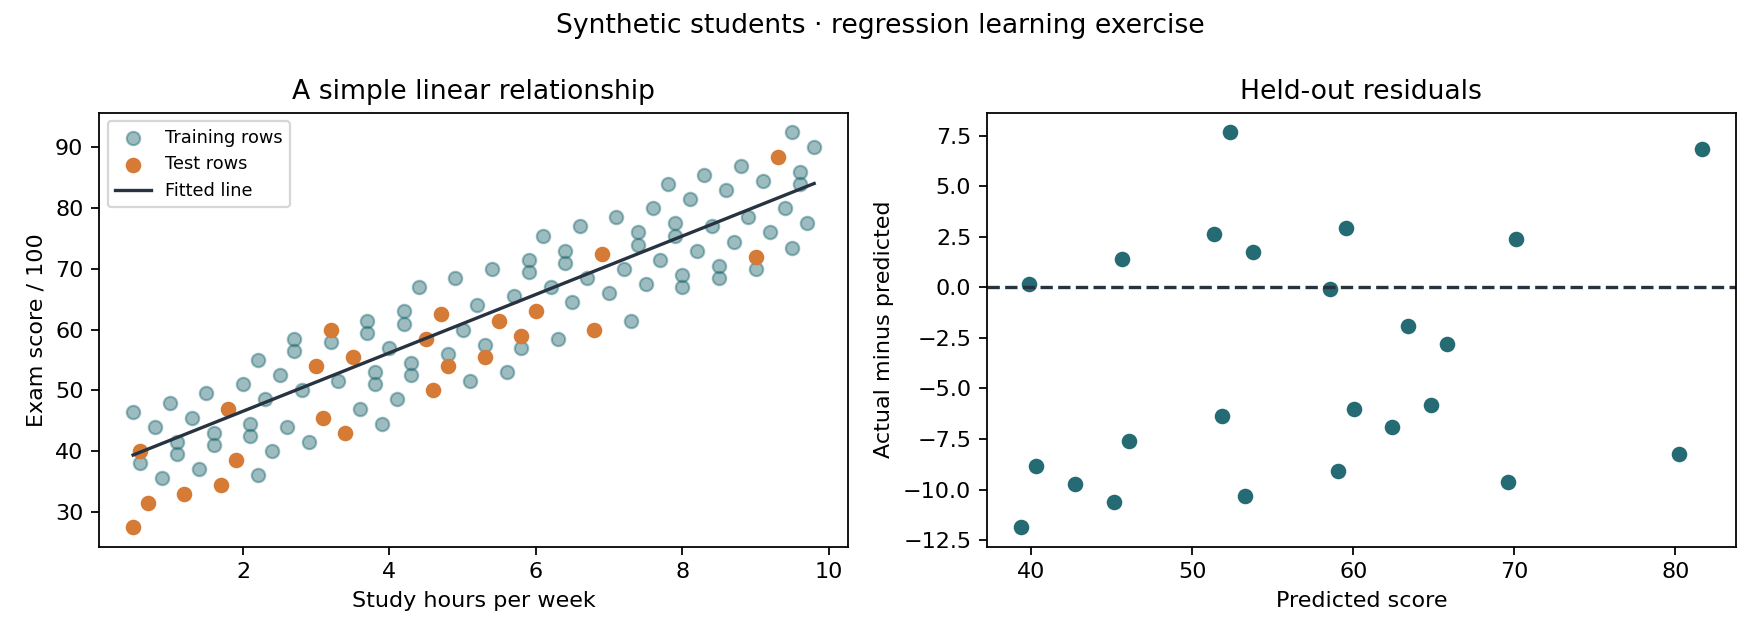

# Regression findings

This is a synthetic learning exercise, not evidence about real students.

Training rows: 96. Test rows: 24. Random seed: 42.

| Model | Test MAE | Test RMSE | Test RÂ² |
|---|---:|---:|---:|
| linear_regression | 5.89 | 6.87 | 0.768 |
| mean_baseline | 13.72 | 17.39 | -0.489 |

Regression improves on the training-mean baseline on this fixed test split. MAE is the average absolute error in score points. The generator deliberately creates a linear relationship, so this is not a claim of real-world prediction quality.



In [6]:
_ = run(hours=4)
display(Image(filename=str(ROOT / 'outputs/regression.png')))
print((ROOT / 'outputs/report.md').read_text())

## Practice
Explain why fitting the imputer before the split would leak information. Calculate five errors manually. If trying more models, use training-set cross-validation and reserve the test set for final evaluation.